# Online Retail Dataset: Data Loading and Preprocessing

**Objective:** To load, inspect, investigate, clean, and validate the Online Retail dataset using Python, Pandas, and NumPy while preserving the original data for comparison.

In [5]:

# MODULE 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from IPython.display import display

print("All required libraries imported successfully.")


All required libraries imported successfully.


In [6]:

# UPLOAD THE ORIGINAL DATASET

uploaded = files.upload()

file_name = next(iter(uploaded.keys()))

print("Uploaded file:", file_name)


Saving Online Retail.xlsx to Online Retail.xlsx
Uploaded file: Online Retail.xlsx


In [7]:

# LOAD THE DATASET

df_original = pd.read_excel(file_name)

# Create a separate working copy for later preprocessing
df = df_original.copy()

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())


Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First five records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [8]:

# ============================================================
# MODULE 2: INITIAL DATA AUDIT
# ============================================================

print("=" * 65)
print("MODULE 2: INITIAL DATA AUDIT")
print("=" * 65)

# 1. Dataset structure
print("\n1. DATASET STRUCTURE")
print("-" * 65)

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Memory usage (MB):",
      round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2))

print("\nColumn names:")
print(df.columns.tolist())

# 2. Data types
print("\n2. DATA TYPES")
print("-" * 65)
print(df.dtypes)

# 3. Missing values
print("\n3. MISSING VALUE REPORT")
print("-" * 65)

missing_report = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Non_Null_Count": df.notna().sum(),
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2),
    "Unique_Values": df.nunique(dropna=True)
})

display(missing_report)

# 4. Duplicate records
print("\n4. DUPLICATE RECORDS")
print("-" * 65)

duplicate_count = df.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)
print("Rows beyond the first copy:", duplicate_count)

# 5. Transaction date coverage
print("\n5. TRANSACTION DATE COVERAGE")
print("-" * 65)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

print("Earliest date:", df["InvoiceDate"].min())
print("Latest date:", df["InvoiceDate"].max())
print("Invalid or missing dates:", df["InvoiceDate"].isna().sum())
print("Unique invoice numbers:", df["InvoiceNo"].nunique())

# 6. Transaction exceptions
print("\n6. TRANSACTION EXCEPTIONS")
print("-" * 65)

print("Cancellation invoice rows:",
      df["InvoiceNo"].astype("string").str.startswith("C", na=False).sum())

print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Zero quantities:", (df["Quantity"] == 0).sum())
print("Negative unit prices:", (df["UnitPrice"] < 0).sum())
print("Zero unit prices:", (df["UnitPrice"] == 0).sum())

print("\nInitial data audit completed.")
print("No records have been intentionally deleted.")


MODULE 2: INITIAL DATA AUDIT

1. DATASET STRUCTURE
-----------------------------------------------------------------
Number of rows: 541909
Number of columns: 8
Memory usage (MB): 126.18

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

2. DATA TYPES
-----------------------------------------------------------------
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object

3. MISSING VALUE REPORT
-----------------------------------------------------------------


,Data_Type,Non_Null_Count,Missing_Count,Missing_Percentage,Unique_Values
InvoiceNo,object,541909,0,0.00,25900
StockCode,object,541909,0,0.00,4070
Description,object,540455,1454,0.27,4223
Quantity,int64,541909,0,0.00,722
InvoiceDate,datetime64[ns],541909,0,0.00,23260
UnitPrice,float64,541909,0,0.00,1630
CustomerID,float64,406829,135080,24.93,4372
Country,object,541909,0,0.00,38



4. DUPLICATE RECORDS
-----------------------------------------------------------------
Exact duplicate rows: 5268
Rows beyond the first copy: 5268

5. TRANSACTION DATE COVERAGE
-----------------------------------------------------------------
Earliest date: 2010-12-01 08:26:00
Latest date: 2011-12-09 12:50:00
Invalid or missing dates: 0
Unique invoice numbers: 25900

6. TRANSACTION EXCEPTIONS
-----------------------------------------------------------------
Cancellation invoice rows: 9288
Negative quantities: 10624
Zero quantities: 0
Negative unit prices: 2
Zero unit prices: 2515

Initial data audit completed.
No records have been intentionally deleted.


In [9]:

# ============================================================
# MODULE 1 - STEP 2: CONTROLLED DATA QUALITY INVESTIGATION
# ============================================================

import pandas as pd
from IPython.display import display

# 1. Preserve the original dataset and create a working copy
# Assumption: the original dataset is stored in `df`.
df_raw = df.copy(deep=True)
df_audit = df_raw.copy(deep=True)

# 2. Validate required columns
required_columns = [
    "InvoiceNo", "Description", "CustomerID",
    "Quantity", "UnitPrice", "InvoiceDate"
]

missing_columns = [
    col for col in required_columns
    if col not in df_audit.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from dataset: {missing_columns}"
    )

# Ensure numeric columns are numeric
df_audit["Quantity"] = pd.to_numeric(
    df_audit["Quantity"], errors="coerce"
)
df_audit["UnitPrice"] = pd.to_numeric(
    df_audit["UnitPrice"], errors="coerce"
)

# 3. Identify data-quality conditions
invoice_text = df_audit["InvoiceNo"].astype("string").str.strip()

is_cancellation = invoice_text.str.upper().str.startswith(
    "C", na=False
)

is_duplicate = df_audit.duplicated(keep="first")

# 4. Build transaction-level audit summary
audit_summary = pd.DataFrame({
    "Check": [
        "Original rows",
        "Exact duplicate rows beyond first occurrence",
        "Missing descriptions",
        "Missing CustomerIDs",
        "Cancellation invoice rows",
        "Negative quantity rows",
        "Zero quantity rows",
        "Negative unit-price rows",
        "Zero unit-price rows",
        "Missing invoice numbers",
        "Missing invoice dates"
    ],
    "Count": [
        len(df_audit),
        int(is_duplicate.sum()),
        int(df_audit["Description"].isna().sum()),
        int(df_audit["CustomerID"].isna().sum()),
        int(is_cancellation.sum()),
        int((df_audit["Quantity"] < 0).sum()),
        int((df_audit["Quantity"] == 0).sum()),
        int((df_audit["UnitPrice"] < 0).sum()),
        int((df_audit["UnitPrice"] == 0).sum()),
        int(df_audit["InvoiceNo"].isna().sum()),
        int(df_audit["InvoiceDate"].isna().sum())
    ]
})

print("TRANSACTION QUALITY AUDIT")
display(audit_summary)

# 5. Inspect cancellation and return examples
print("\nCANCELLATION INVOICE EXAMPLES")
display(df_audit.loc[is_cancellation].head(10))

print("\nNEGATIVE QUANTITY EXAMPLES")
display(df_audit.loc[df_audit["Quantity"] < 0].head(10))

print("\nZERO-PRICE TRANSACTION EXAMPLES")
display(df_audit.loc[df_audit["UnitPrice"] == 0].head(10))

# 6. Document the cleaning policy
print("""
CLEANING POLICY
---------------
1. Preserve df_raw unchanged.
2. Remove exact duplicate rows from the analytical copy.
3. Exclude cancellation invoices from the initial sales dataset.
4. Exclude non-positive quantities and prices from positive-sales analysis.
5. Retain missing CustomerIDs for overall sales analysis.
6. Retain missing descriptions; flag them for product-level analysis.
7. Keep the original records available for separate investigation.
""")

# 7. Remove exact duplicates
df_deduplicated = df_audit.drop_duplicates(
    keep="first"
).copy()

# 8. Identify positive sales transactions
invoice_text_deduplicated = (
    df_deduplicated["InvoiceNo"]
    .astype("string")
    .str.strip()
)

is_not_cancellation = (
    ~invoice_text_deduplicated.str.upper().str.startswith(
        "C", na=False
    )
)

valid_sales_mask = (
    is_not_cancellation
    & (df_deduplicated["Quantity"] > 0)
    & (df_deduplicated["UnitPrice"] > 0)
    & df_deduplicated["InvoiceDate"].notna()
    & df_deduplicated["InvoiceNo"].notna()
)

sales_df = df_deduplicated.loc[
    valid_sales_mask
].copy()

# 9. Calculate line revenue
sales_df["Revenue"] = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
)

# 10. Report results
print("\nCLEANING RESULTS")
print("-" * 50)
print(f"Original rows:              {len(df_raw):,}")
print(f"After deduplication:        {len(df_deduplicated):,}")
print(f"Positive sales rows:        {len(sales_df):,}")
print(
    "Rows removed as duplicates: "
    f"{len(df_raw) - len(df_deduplicated):,}"
)
print(
    "Rows excluded from sales analysis: "
    f"{len(df_deduplicated) - len(sales_df):,}"
)
print(
    "Calculated sales revenue: "
    f"{sales_df['Revenue'].sum():,.2f}"
)

print("\nSALES DATA PREVIEW")
display(sales_df.head())

print(
    "\nMissing CustomerIDs retained:",
    f"{sales_df['CustomerID'].isna().sum():,}"
)

print("\nCleaning step completed.")


TRANSACTION QUALITY AUDIT


,Check,Count
0,Original rows,541909
1,Exact duplicate rows beyond first occurrence,5268
2,Missing descriptions,1454
3,Missing CustomerIDs,135080
4,Cancellation invoice rows,9288
5,Negative quantity rows,10624
6,Zero quantity rows,0
7,Negative unit-price rows,2
8,Zero unit-price rows,2515
9,Missing invoice numbers,0



CANCELLATION INVOICE EXAMPLES


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom



NEGATIVE QUANTITY EXAMPLES


...


ZERO-PRICE TRANSACTION EXAMPLES


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
1988,536550,85044,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2024,536552,20950,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom
2025,536553,37461,NaN,3,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2026,536554,84670,NaN,23,2010-12-01 14:35:00,0.0,NaN,United Kingdom
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom



CLEANING POLICY
---------------
1. Preserve df_raw unchanged.
2. Remove exact duplicate rows from the analytical copy.
3. Exclude cancellation invoices from the initial sales dataset.
4. Exclude non-positive quantities and prices from positive-sales analysis.
5. Retain missing CustomerIDs for overall sales analysis.
6. Retain missing descriptions; flag them for product-level analysis.
7. Keep the original records available for separate investigation.


CLEANING RESULTS
--------------------------------------------------
Original rows:              541,909
After deduplication:        536,641
Positive sales rows:        524,878
Rows removed as duplicates: 5,268
Rows excluded from sales analysis: 11,763
Calculated sales revenue: 10,642,110.80

SALES DATA PREVIEW


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34



Missing CustomerIDs retained: 132,186

Cleaning step completed.


In [10]:

# RETAIL SALES ANALYTICS
# Stage 2: Cleaning Validation — Diagnostic Check
# Purpose: Inspect existing DataFrames without modifying them.

import pandas as pd

print("=" * 65)
print("RETAIL SALES ANALYTICS | DATAFRAME DIAGNOSTIC")
print("=" * 65)

# Identify existing DataFrames in the notebook
dataframes = {
    name: obj
    for name, obj in globals().copy().items()
    if isinstance(obj, pd.DataFrame)
}

if not dataframes:
    print("No pandas DataFrames found in the current session.")
else:
    for name, data in dataframes.items():
        print(f"\nDataFrame: {name}")
        print(f"Rows: {len(data):,}")
        print(f"Columns: {len(data.columns)}")
        print(f"Column names: {data.columns.tolist()}")

        # Check whether a revenue column already exists
        revenue_col = next(
            (col for col in data.columns
             if str(col).strip().lower() in
             ["revenue", "sales", "total_sales"]),
            None
        )

        if revenue_col is not None:
            print(
                f"Existing {revenue_col} total: "
                f"{data[revenue_col].sum():,.2f}"
            )

print("\n" + "=" * 65)
print("Diagnostic complete. No DataFrame was modified.")
print("=" * 65)


RETAIL SALES ANALYTICS | DATAFRAME DIAGNOSTIC

DataFrame: df_original
Rows: 541,909
Columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DataFrame: df
Rows: 541,909
Columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DataFrame: missing_report
Rows: 8
Columns: 5
Column names: ['Data_Type', 'Non_Null_Count', 'Missing_Count', 'Missing_Percentage', 'Unique_Values']

DataFrame: df_raw
Rows: 541,909
Columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DataFrame: df_audit
Rows: 541,909
Columns: 8
Column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

DataFrame: audit_summary
Rows: 11
Columns: 2
Column names: ['Check', 'Count']

DataFrame: df_deduplicated
Rows: 536,641
Columns: 8
Column name

In [11]:
# RETAIL SALES ANALYTICS
# STEP 2: POST-CLEANING VALIDATION

import pandas as pd
import numpy as np

print("=" * 65)
print("RETAIL SALES ANALYTICS | POST-CLEANING VALIDATION")
print("=" * 65)

# 1. Verify dataset structure
print("\n1. DATASET STRUCTURE")
print("Rows:", len(sales_df))
print("Columns:", sales_df.shape[1])
print("Duplicate rows remaining:", sales_df.duplicated().sum())

# 2. Verify missing values
print("\n2. MISSING VALUES")
print(sales_df.isnull().sum())

# 3. Verify transaction values
print("\n3. SALES VALIDATION")
print("Non-positive quantities:", (sales_df["Quantity"] <= 0).sum())
print("Non-positive unit prices:", (sales_df["UnitPrice"] <= 0).sum())

# 4. Independently recalculate revenue
calculated_revenue = (
    sales_df["Quantity"] * sales_df["UnitPrice"]
).sum()

print("\n4. REVENUE RECONCILIATION")
print(f"Recalculated revenue: {calculated_revenue:,.2f}")

if "Revenue" in sales_df.columns:
    stored_revenue = sales_df["Revenue"].sum()
    print(f"Stored revenue total:  {stored_revenue:,.2f}")
    print(
        "Revenue matches:",
        np.isclose(calculated_revenue, stored_revenue)
    )

# 5. Check date range
print("\n5. TRANSACTION DATE RANGE")
print("Earliest:", sales_df["InvoiceDate"].min())
print("Latest:  ", sales_df["InvoiceDate"].max())

print("\nValidation completed. No data was modified.")
print("=" * 65)

RETAIL SALES ANALYTICS | POST-CLEANING VALIDATION

1. DATASET STRUCTURE
Rows: 524878
Columns: 9
Duplicate rows remaining: 0

2. MISSING VALUES
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

3. SALES VALIDATION
Non-positive quantities: 0
Non-positive unit prices: 0

4. REVENUE RECONCILIATION
Recalculated revenue: 10,642,110.80
Stored revenue total:  10,642,110.80
Revenue matches: True

5. TRANSACTION DATE RANGE
Earliest: 2010-12-01 08:26:00
Latest:   2011-12-09 12:50:00

Validation completed. No data was modified.


In [12]:

# ==========================================
# RETAIL SALES ANALYTICS | KPI BASELINE
# ==========================================

# Use the existing cleaned dataset
# Create a separate copy for analysis
eda_df = sales_df.copy()

# Ensure the date column is in datetime format
eda_df["InvoiceDate"] = pd.to_datetime(
    eda_df["InvoiceDate"], errors="coerce"
)

# Recalculate revenue for validation
eda_df["Revenue"] = (
    eda_df["Quantity"] * eda_df["UnitPrice"]
)

# Validate data before calculating KPIs
assert eda_df["InvoiceDate"].notna().all(), \
    "Invalid invoice dates detected."

assert (eda_df["Quantity"] > 0).all(), \
    "Non-positive quantities detected."

assert (eda_df["UnitPrice"] > 0).all(), \
    "Non-positive unit prices detected."

# Calculate business KPIs
total_revenue = eda_df["Revenue"].sum()
total_units = eda_df["Quantity"].sum()
unique_invoices = eda_df["InvoiceNo"].nunique()
unique_products = eda_df["StockCode"].nunique()
unique_countries = eda_df["Country"].nunique()

average_order_value = (
    total_revenue / unique_invoices
    if unique_invoices > 0 else 0
)

# Display results
print("=" * 55)
print("RETAIL SALES ANALYTICS | KPI BASELINE")
print("=" * 55)

print(f"Total Revenue:       £{total_revenue:,.2f}")
print(f"Total Units Sold:    {total_units:,.0f}")
print(f"Unique Invoices:     {unique_invoices:,}")
print(f"Unique Products:     {unique_products:,}")
print(f"Countries Served:    {unique_countries:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")

print("=" * 55)
print("KPI calculation completed.")


RETAIL SALES ANALYTICS | KPI BASELINE
Total Revenue:       £10,642,110.80
Total Units Sold:    5,572,420
Unique Invoices:     19,960
Unique Products:     3,922
Countries Served:    38
Average Order Value: £533.17
KPI calculation completed.


In [13]:

# ==========================================
# RETAIL SALES ANALYTICS | MONTHLY TRENDS
# ==========================================

monthly_sales = (
    eda_df
    .assign(Month=eda_df["InvoiceDate"].dt.to_period("M"))
    .groupby("Month", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .sort_values("Month")
)

# Calculate month-over-month revenue change
monthly_sales["Revenue_MoM_Change_%"] = (
    monthly_sales["Revenue"].pct_change() * 100
)

# Format the month for readable output
monthly_sales["Month"] = monthly_sales["Month"].astype(str)

print("=" * 75)
print("RETAIL SALES ANALYTICS | MONTHLY REVENUE TRENDS")
print("=" * 75)

print(monthly_sales.round(2).to_string(index=False))

print("\nMONTHLY TREND SUMMARY")
print("-" * 75)

best_month = monthly_sales.loc[monthly_sales["Revenue"].idxmax()]
worst_month = monthly_sales.loc[monthly_sales["Revenue"].idxmin()]

print(f"Highest revenue month: {best_month['Month']}")
print(f"Highest monthly revenue: £{best_month['Revenue']:,.2f}")
print(f"Lowest revenue month: {worst_month['Month']}")
print(f"Lowest monthly revenue: £{worst_month['Revenue']:,.2f}")

print("=" * 75)


RETAIL SALES ANALYTICS | MONTHLY REVENUE TRENDS
  Month    Revenue  Units_Sold  Unique_Invoices  Revenue_MoM_Change_%
2010-12  821452.73      358019             1559                   NaN
2011-01  689811.61      387099             1086                -16.03
2011-02  522545.56      282934             1100                -24.25
2011-03  716215.26      376599             1454                 37.06
2011-04  536968.49      307953             1246                -25.03
2011-05  769296.61      395001             1681                 43.27
2011-06  760547.01      388511             1533                 -1.14
2011-07  718076.12      399693             1475                 -5.58
2011-08  757841.38      421020             1361                  5.54
2011-09 1056435.19      569573             1837                 39.40
2011-10 1151263.73      621029             2040                  8.98
2011-11 1503866.78      751377             2769                 30.63
2011-12  637790.33      313612            

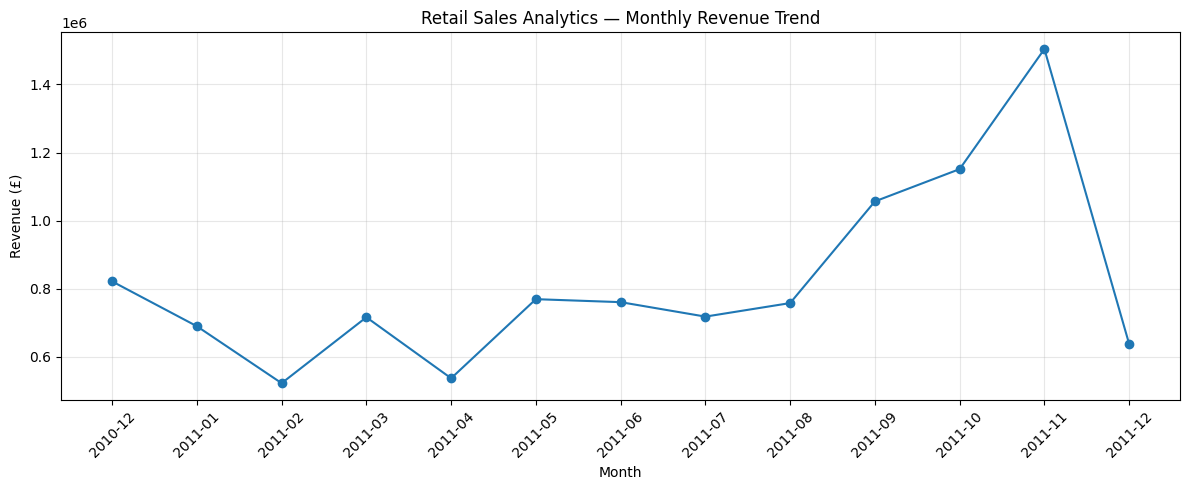

In [14]:

import matplotlib.pyplot as plt

# Monthly revenue trend
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Month"],
    monthly_sales["Revenue"],
    marker="o"
)

plt.title("Retail Sales Analytics — Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [15]:
# RETAIL SALES ANALYTICS | REVENUE DRIVER ANALYSIS

# 1. Revenue by country
country_revenue = (
    sales_df.groupby("Country", as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

country_revenue["Revenue_Share_%"] = (
    country_revenue["Revenue"]
    / country_revenue["Revenue"].sum() * 100
)

print("=" * 65)
print("TOP 10 COUNTRIES BY REVENUE")
print("=" * 65)
print(country_revenue.head(10).round(2).to_string(index=False))

# 2. Revenue by product
product_revenue = (
    sales_df.groupby(["StockCode", "Description"], as_index=False)
    .agg(
        Revenue=("Revenue", "sum"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_values("Revenue", ascending=False)
)

print("\n" + "=" * 65)
print("TOP 10 PRODUCTS BY REVENUE")
print("=" * 65)
print(product_revenue.head(10).round(2).to_string(index=False))

# 3. Validation
print("\n" + "=" * 65)
print("REVENUE RECONCILIATION")
print("=" * 65)
print(f"Country revenue total: £{country_revenue['Revenue'].sum():,.2f}")
print(f"Product revenue total: £{product_revenue['Revenue'].sum():,.2f}")
print(f"Sales DataFrame rows: {len(sales_df):,}")

TOP 10 COUNTRIES BY REVENUE
       Country    Revenue  Units_Sold  Unique_Invoices  Revenue_Share_%
United Kingdom 9001744.09     4646906            18019            84.59
   Netherlands  285446.34      200361               94             2.68
          EIRE  283140.52      147007              288             2.66
       Germany  228678.40      119154              457             2.15
        France  209625.37      112060              392             1.97
     Australia  138453.81       83891               57             1.30
         Spain   61558.56       27933               90             0.58
   Switzerland   57067.60       30617               54             0.54
       Belgium   41196.34       23237               98             0.39
        Sweden   38367.83       36078               36             0.36

TOP 10 PRODUCTS BY REVENUE
StockCode                        Description   Revenue  Units_Sold
      DOT                     DOTCOM POSTAGE 206248.77         706
    22423         

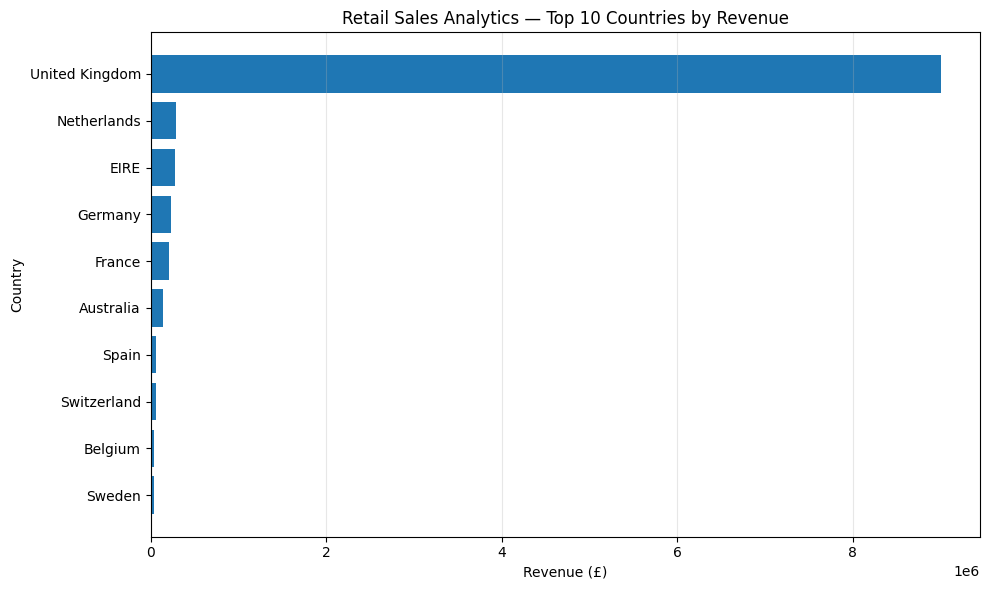

In [16]:
import matplotlib.pyplot as plt

# Top 10 countries by revenue
top_countries = country_revenue.head(10).sort_values("Revenue")

plt.figure(figsize=(10, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Revenue"]
)

plt.title("Retail Sales Analytics — Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# RETAIL SALES ANALYTICS | CUSTOMER REVENUE ANALYSIS

# Exclude transactions without a customer ID for customer-level analysis
customer_sales = sales_df.dropna(subset=["CustomerID"]).copy()

# Aggregate revenue and purchasing activity by customer
customer_summary = (
    customer_sales.groupby("CustomerID", as_index=False)
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Units=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Revenue contribution
total_customer_revenue = customer_summary["Total_Revenue"].sum()

customer_summary["Revenue_Share_%"] = (
    customer_summary["Total_Revenue"]
    / total_customer_revenue * 100
)

# Cumulative contribution, sorted from highest to lowest revenue
customer_summary["Cumulative_Revenue_Share_%"] = (
    customer_summary["Revenue_Share_%"].cumsum()
)

print("=" * 65)
print("RETAIL SALES ANALYTICS | TOP 10 CUSTOMERS")
print("=" * 65)

print(
    customer_summary.head(10).round(2).to_string(index=False)
)

print("\n" + "=" * 65)
print("CUSTOMER CONCENTRATION SUMMARY")
print("=" * 65)

print(f"Customers analyzed: {len(customer_summary):,}")
print(f"Revenue from identified customers: £{total_customer_revenue:,.2f}")
print(
    f"Top 10 customers' revenue share: "
    f"{customer_summary.head(10)['Revenue_Share_%'].sum():.2f}%"
)

print("\nCustomer analysis completed.")

RETAIL SALES ANALYTICS | TOP 10 CUSTOMERS
 CustomerID  Total_Revenue  Total_Units  Unique_Invoices  Revenue_Share_%  Cumulative_Revenue_Share_%
    14646.0      280206.02       196915               73             3.15                        3.15
    18102.0      259657.30        64124               60             2.92                        6.07
    17450.0      194390.79        69973               46             2.19                        8.26
    16446.0      168472.50        80997                2             1.90                       10.16
    14911.0      143711.17        80240              201             1.62                       11.77
    12415.0      124914.53        77374               21             1.41                       13.18
    14156.0      117210.08        57768               55             1.32                       14.50
    17511.0       91062.38        64549               31             1.02                       15.52
    16029.0       80850.84        40108 

In [18]:

# ============================================================
# MODULE 3: RFM CUSTOMER SEGMENTATION
# Using the existing cleaned sales_df dataset
# ============================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("=" * 65)
print("RETAIL SALES ANALYTICS | RFM CUSTOMER SEGMENTATION")
print("=" * 65)

# 1. Prepare customer-level transaction data
rfm_source = sales_df.dropna(
    subset=["CustomerID", "InvoiceNo", "InvoiceDate"]
).copy()

# Ensure dates and revenue are in the correct format
rfm_source["InvoiceDate"] = pd.to_datetime(
    rfm_source["InvoiceDate"], errors="coerce"
)
rfm_source = rfm_source.dropna(subset=["InvoiceDate", "Revenue"])

# Keep the original cleaned dataset unchanged
rfm_source = rfm_source[
    rfm_source["Quantity"].gt(0) &
    rfm_source["UnitPrice"].gt(0) &
    rfm_source["Revenue"].gt(0)
].copy()

# 2. Set the reference date
reference_date = rfm_source["InvoiceDate"].max() + pd.Timedelta(days=1)

# 3. Calculate RFM metrics for each identified customer
rfm_df = (
    rfm_source.groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x:
                 (reference_date - x.max()).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

print("\n1. RFM DATASET SUMMARY")
print("-" * 65)
print(f"Customers included: {len(rfm_df):,}")
print(f"Reference date: {reference_date}")
print(f"Missing RFM values: {rfm_df[['Recency', 'Frequency', 'Monetary']].isna().sum().sum()}")

print("\n2. RFM DESCRIPTIVE STATISTICS")
print("-" * 65)
print(rfm_df[["Recency", "Frequency", "Monetary"]].describe().round(2))

# 4. Transform skewed values and standardize the features
rfm_features = rfm_df[["Recency", "Frequency", "Monetary"]].copy()
rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# 5. Apply K-Means clustering
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm_df["Cluster"] = kmeans.fit_predict(rfm_scaled)

print("\n3. CUSTOMER CLUSTER COUNTS")
print("-" * 65)
print(rfm_df["Cluster"].value_counts().sort_index())

print("\n4. CLUSTER BEHAVIOUR SUMMARY")
print("-" * 65)
cluster_summary = (
    rfm_df.groupby("Cluster")
    .agg(
        Customers=("CustomerID", "count"),
        Avg_Recency_Days=("Recency", "mean"),
        Avg_Invoices=("Frequency", "mean"),
        Avg_Revenue=("Monetary", "mean"),
        Total_Revenue=("Monetary", "sum")
    )
    .round(2)
)

cluster_summary["Revenue_Share_%"] = (
    cluster_summary["Total_Revenue"]
    / rfm_df["Monetary"].sum() * 100
).round(2)

print(cluster_summary)

# 6. Validate the segmentation
print("\n5. VALIDATION")
print("-" * 65)
print(f"Total customers: {len(rfm_df):,}")
print(f"Customers assigned to clusters: {rfm_df['Cluster'].notna().sum():,}")
print(f"Duplicate customer records: {rfm_df['CustomerID'].duplicated().sum()}")
print(f"Total RFM revenue: £{rfm_df['Monetary'].sum():,.2f}")
print(f"Revenue matches source: {np.isclose(rfm_df['Monetary'].sum(), rfm_source['Revenue'].sum())}")

assert rfm_df["Cluster"].notna().all()
assert rfm_df["CustomerID"].is_unique

print("\nRFM CUSTOMER SEGMENTATION COMPLETED.")


RETAIL SALES ANALYTICS | RFM CUSTOMER SEGMENTATION

1. RFM DATASET SUMMARY
-----------------------------------------------------------------
Customers included: 4,338
Reference date: 2011-12-10 12:50:00
Missing RFM values: 0

2. RFM DESCRIPTIVE STATISTICS
-----------------------------------------------------------------
       Recency  Frequency   Monetary
count  4338.00    4338.00    4338.00
mean     92.54       4.27    2048.69
std     100.01       7.70    8985.23
min       1.00       1.00       3.75
25%      18.00       1.00     306.48
50%      51.00       2.00     668.57
75%     142.00       5.00    1660.60
max     374.00     209.00  280206.02

3. CUSTOMER CLUSTER COUNTS
-----------------------------------------------------------------
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64

4. CLUSTER BEHAVIOUR SUMMARY
-----------------------------------------------------------------
         Customers  Avg_Recency_Days  Avg_Invoices  Avg_Revenue  \
Cluster       

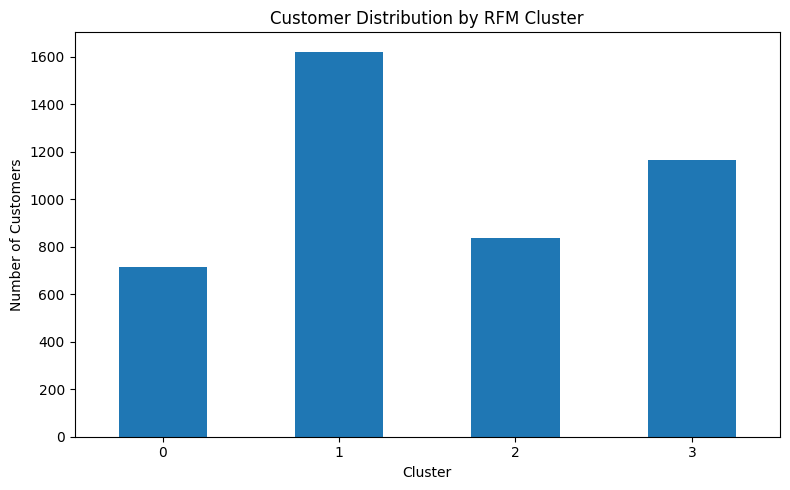

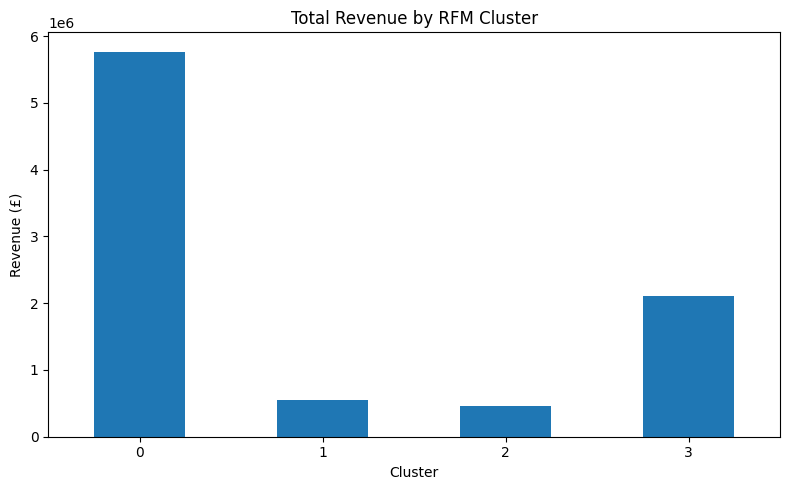

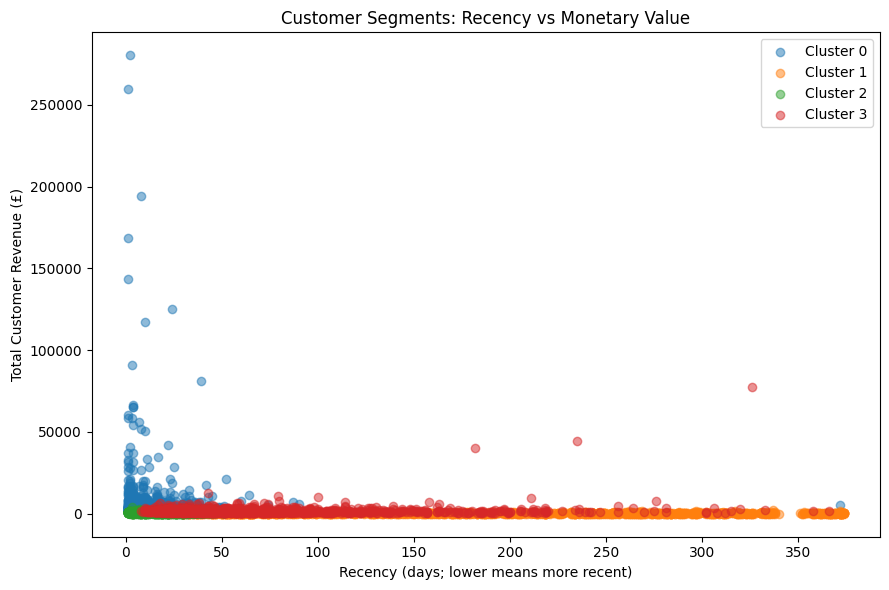

RFM visualization completed.


In [19]:

import matplotlib.pyplot as plt

# 1. Customer count by cluster
plt.figure(figsize=(8, 5))
rfm_df["Cluster"].value_counts().sort_index().plot(kind="bar")
plt.title("Customer Distribution by RFM Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Revenue contribution by cluster
plt.figure(figsize=(8, 5))
cluster_summary["Total_Revenue"].sort_index().plot(kind="bar")
plt.title("Total Revenue by RFM Cluster")
plt.xlabel("Cluster")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. Recency versus monetary value
plt.figure(figsize=(9, 6))
for cluster in sorted(rfm_df["Cluster"].unique()):
    data = rfm_df[rfm_df["Cluster"] == cluster]
    plt.scatter(
        data["Recency"],
        data["Monetary"],
        label=f"Cluster {cluster}",
        alpha=0.5
    )

plt.title("Customer Segments: Recency vs Monetary Value")
plt.xlabel("Recency (days; lower means more recent)")
plt.ylabel("Total Customer Revenue (£)")
plt.legend()
plt.tight_layout()
plt.show()

print("RFM visualization completed.")


In [20]:
# Module 4 — Inspect existing dataset and variables
print("Available DataFrames:")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}: {obj.shape}")
        print("Columns:", obj.columns.tolist())

Available DataFrames:

df_original: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

df: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

missing_report: (8, 5)
Columns: ['Data_Type', 'Non_Null_Count', 'Missing_Count', 'Missing_Percentage', 'Unique_Values']

df_raw: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

df_audit: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

audit_summary: (11, 2)
Columns: ['Check', 'Count']

df_deduplicated: (536641, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

sales_df: (524878, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPr

In [21]:

# Module 4 — Verify cleaned transaction data

print("sales_df:", sales_df.shape)
print(sales_df.columns.tolist())
print(sales_df[["CustomerID", "InvoiceDate", "InvoiceNo"]].head())


sales_df: (524878, 9)
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
   CustomerID         InvoiceDate InvoiceNo
0     17850.0 2010-12-01 08:26:00    536365
1     17850.0 2010-12-01 08:26:00    536365
2     17850.0 2010-12-01 08:26:00    536365
3     17850.0 2010-12-01 08:26:00    536365
4     17850.0 2010-12-01 08:26:00    536365


In [22]:

# Module 4 — Final Data Quality Validation

import pandas as pd

print("Dataset shape:", sales_df.shape)
print("\nMissing values:")
print(sales_df.isnull().sum())

print("\nDuplicate rows:", sales_df.duplicated().sum())

print("\nNegative or zero quantities:")
print("Quantity <= 0:", (sales_df["Quantity"] <= 0).sum())

print("\nInvalid unit prices:")
print("UnitPrice <= 0:", (sales_df["UnitPrice"] <= 0).sum())

print("\nMissing customer IDs:",
      sales_df["CustomerID"].isna().sum())

print("\nInvoice number sample:")
print(sales_df["InvoiceNo"].astype(str).head(10).tolist())

print("\nDate range:")
print(sales_df["InvoiceDate"].min(),
      "to", sales_df["InvoiceDate"].max())

print("\nValidation completed.")


Dataset shape: (524878, 9)

Missing values:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132186
Country             0
Revenue             0
dtype: int64

Duplicate rows: 0

Negative or zero quantities:
Quantity <= 0: 0

Invalid unit prices:
UnitPrice <= 0: 0

Missing customer IDs: 132186

Invoice number sample:
['536365', '536365', '536365', '536365', '536365', '536365', '536365', '536366', '536366', '536367']

Date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00

Validation completed.


## Module 4 — Predictive Machine Learning
### Customer Repeat Purchase Prediction

**Objective:** Predict whether a customer will make another purchase within the next 30 days using historical transaction data.

**Approach:**
1. Prepare customer-level transaction history.
2. Define the 30-day repeat-purchase target.
3. Engineer predictive features without data leakage.
4. Train Logistic Regression and Random Forest models.
5. Evaluate and compare model performance.


In [23]:

# Module 4 - Step 1: Inspect transaction data for prediction

print("Dataset shape:", sales_df.shape)
print("\nAvailable columns:")
print(sales_df.columns.tolist())

print("\nTransaction date range:")
print("Start:", sales_df["InvoiceDate"].min())
print("End:", sales_df["InvoiceDate"].max())

print("\nUnique customers:", sales_df["CustomerID"].nunique())
print("Unique invoices:", sales_df["InvoiceNo"].nunique())

print("\nSample transactions:")
display(
    sales_df[
        ["CustomerID", "InvoiceDate", "InvoiceNo",
         "Quantity", "UnitPrice", "Revenue"]
    ].head()
)


Dataset shape: (524878, 9)

Available columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Transaction date range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Unique customers: 4338
Unique invoices: 19960

Sample transactions:


,CustomerID,InvoiceDate,InvoiceNo,Quantity,UnitPrice,Revenue
0,17850.0,2010-12-01 08:26:00,536365,6,2.55,15.30
1,17850.0,2010-12-01 08:26:00,536365,6,3.39,20.34
2,17850.0,2010-12-01 08:26:00,536365,8,2.75,22.00
3,17850.0,2010-12-01 08:26:00,536365,6,3.39,20.34
4,17850.0,2010-12-01 08:26:00,536365,6,3.39,20.34


In [24]:

# Module 4 - Step 2: Prepare customer-level transaction history

import pandas as pd
import numpy as np

# Work on a separate copy; preserve the cleaned dataset
transactions = sales_df.copy()

# Ensure correct data types
transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"]
)
transactions["CustomerID"] = pd.to_numeric(
    transactions["CustomerID"], errors="coerce"
)

# Remove rows without customer IDs for customer-level modelling
transactions = transactions.dropna(
    subset=["CustomerID", "InvoiceDate"]
).copy()

# Exclude cancelled invoices (invoice numbers beginning with C)
transactions = transactions[
    ~transactions["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep actual purchase transactions with positive quantities
transactions = transactions[
    transactions["Quantity"] > 0
].copy()

# Summarize purchases at customer-invoice level
customer_invoices = (
    transactions.groupby(
        ["CustomerID", "InvoiceNo"], as_index=False
    )
    .agg(
        InvoiceDate=("InvoiceDate", "min"),
        InvoiceRevenue=("Revenue", "sum")
    )
)

print("Customer-level modelling data prepared.")
print("Transaction rows:", len(transactions))
print("Customers:", transactions["CustomerID"].nunique())
print("Purchase invoices:", customer_invoices["InvoiceNo"].nunique())
print("Date range:",
      transactions["InvoiceDate"].min(),
      "to",
      transactions["InvoiceDate"].max())

display(customer_invoices.head())


Customer-level modelling data prepared.
Transaction rows: 392692
Customers: 4338
Purchase invoices: 18532
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,CustomerID,InvoiceNo,InvoiceDate,InvoiceRevenue
0,12346.0,541431,2011-01-18 10:01:00,77183.60
1,12347.0,537626,2010-12-07 14:57:00,711.79
2,12347.0,542237,2011-01-26 14:30:00,475.39
3,12347.0,549222,2011-04-07 10:43:00,636.25
4,12347.0,556201,2011-06-09 13:01:00,382.52


In [25]:

# Module 4 - Step 3: Check possible prediction cutoff dates

data_end = transactions["InvoiceDate"].max()

print("Last available transaction:", data_end)
print("\nPossible cutoff dates:")

for cutoff in ["2011-09-30", "2011-10-15", "2011-10-31"]:
    cutoff = pd.Timestamp(cutoff)

    history_count = (
        transactions["InvoiceDate"] < cutoff
    ).sum()

    future_count = (
        (transactions["InvoiceDate"] >= cutoff) &
        (transactions["InvoiceDate"] < cutoff + pd.Timedelta(days=30))
    ).sum()

    print(
        f"Cutoff: {cutoff.date()} | "
        f"Historical rows: {history_count:,} | "
        f"Next 30-day rows: {future_count:,}"
    )


Last available transaction: 2011-12-09 12:50:00

Possible cutoff dates:
Cutoff: 2011-09-30 | Historical rows: 262,254 | Next 30-day rows: 45,574
Cutoff: 2011-10-15 | Historical rows: 285,994 | Next 30-day rows: 51,853
Cutoff: 2011-10-31 | Historical rows: 310,678 | Next 30-day rows: 62,884


In [26]:

# Module 4 - Step 4: Build the prediction dataset

cutoff = pd.Timestamp("2011-10-31")
prediction_end = cutoff + pd.Timedelta(days=30)

# Historical transactions: strictly before cutoff
history = transactions[
    transactions["InvoiceDate"] < cutoff
].copy()

# Future transactions: used ONLY to create the target label
future = transactions[
    (transactions["InvoiceDate"] >= cutoff) &
    (transactions["InvoiceDate"] < prediction_end)
].copy()

# Create customer features using historical data only
reference_date = cutoff

features = history.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    FirstPurchase=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    TotalRevenue=("Revenue", "sum"),
    TotalQuantity=("Quantity", "sum"),
    AverageOrderValue=("Revenue", "sum")
).reset_index()

# Derive recency, customer tenure, and average invoice value
features["RecencyDays"] = (
    reference_date - features["LastPurchase"]
).dt.days

features["TenureDays"] = (
    reference_date - features["FirstPurchase"]
).dt.days

features["AverageOrderValue"] = (
    features["TotalRevenue"] / features["Frequency"]
)

# Label = 1 if customer purchases in the next 30 days, else 0
repeat_customers = future["CustomerID"].unique()

features["RepeatPurchase30D"] = (
    features["CustomerID"].isin(repeat_customers).astype(int)
)

# Remove date columns; keep modelling features and target
model_df = features[
    [
        "CustomerID",
        "RecencyDays",
        "TenureDays",
        "Frequency",
        "TotalRevenue",
        "TotalQuantity",
        "AverageOrderValue",
        "RepeatPurchase30D"
    ]
].copy()

print("Prediction cutoff:", cutoff.date())
print("Prediction window ends:", prediction_end.date())
print("Customers in modelling dataset:", len(model_df))

print("\nTarget distribution:")
print(model_df["RepeatPurchase30D"].value_counts())
print("\nTarget percentages:")
print(
    (model_df["RepeatPurchase30D"].value_counts(normalize=True) * 100)
    .round(2)
)

print("\nMissing values:")
print(model_df.isnull().sum())

display(model_df.head())


Prediction cutoff: 2011-10-31
Prediction window ends: 2011-11-30
Customers in modelling dataset: 3965

Target distribution:
RepeatPurchase30D
0    2635
1    1330
Name: count, dtype: int64

Target percentages:
RepeatPurchase30D
0    66.46
1    33.54
Name: proportion, dtype: float64

Missing values:
CustomerID           0
RecencyDays          0
TenureDays           0
Frequency            0
TotalRevenue         0
TotalQuantity        0
AverageOrderValue    0
RepeatPurchase30D    0
dtype: int64


,CustomerID,RecencyDays,TenureDays,Frequency,TotalRevenue,TotalQuantity,AverageOrderValue,RepeatPurchase30D
0,12346.0,285,285,1,77183.60,74215,77183.600000,0
1,12347.0,89,327,5,2790.86,1590,558.172000,1
2,12348.0,35,318,4,1797.24,2341,449.310000,0
3,12350.0,270,270,1,334.40,197,334.400000,0
4,12352.0,32,256,7,2194.31,409,313.472857,1


In [27]:

# Module 5 - Prepare data for predictive modeling

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Use the existing customer-level modeling dataset
target = "RepeatPurchase30D"

feature_cols = [
    "RecencyDays",
    "TenureDays",
    "Frequency",
    "TotalRevenue",
    "TotalQuantity",
    "AverageOrderValue"
]

# Keep only the required features and target
model_data = model_df[feature_cols + [target]].copy()
model_data = model_data.dropna()

X = model_data[feature_cols]
y = model_data[target].astype(int)

print("Modeling dataset shape:", model_data.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget percentages:")
print((y.value_counts(normalize=True) * 100).round(2))

# Split data while preserving the target class proportions
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining customers:", len(X_train))
print("Testing customers:", len(X_test))
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))


Modeling dataset shape: (3965, 7)

Target distribution:
RepeatPurchase30D
0    2635
1    1330
Name: count, dtype: int64

Target percentages:
RepeatPurchase30D
0    66.46
1    33.54
Name: proportion, dtype: float64

Training customers: 3172
Testing customers: 793

Training target distribution:
RepeatPurchase30D
0    0.665
1    0.335
Name: proportion, dtype: float64

Testing target distribution:
RepeatPurchase30D
0    0.665
1    0.335
Name: proportion, dtype: float64


In [28]:

# Module 5 - Train the baseline Logistic Regression model

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train using only the training data
logistic_model.fit(X_train, y_train)

# Predict on the unseen test data
y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

# Evaluate model performance
print("LOGISTIC REGRESSION - BASELINE RESULTS")
print("-" * 45)
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print("Precision:", round(precision_score(y_test, y_pred_lr, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_lr, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_lr, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_lr,
    target_names=["No Repeat Purchase", "Repeat Purchase"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))


LOGISTIC REGRESSION - BASELINE RESULTS
---------------------------------------------
Accuracy: 0.6847
Precision: 0.5284
Recall: 0.5602
F1-score: 0.5438
ROC-AUC: 0.7156

Classification Report:
                    precision    recall  f1-score   support

No Repeat Purchase       0.77      0.75      0.76       527
   Repeat Purchase       0.53      0.56      0.54       266

          accuracy                           0.68       793
         macro avg       0.65      0.65      0.65       793
      weighted avg       0.69      0.68      0.69       793

Confusion Matrix:
[[394 133]
 [117 149]]


In [29]:

# Module 5 - Random Forest Model Comparison

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# Train the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

# Generate predictions
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model
print("RANDOM FOREST - MODEL RESULTS")
print("-" * 40)

print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf, zero_division=0):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["No Repeat Purchase", "Repeat Purchase"],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


RANDOM FOREST - MODEL RESULTS
----------------------------------------
Accuracy:  0.6948
Precision: 0.5448
Recall:    0.5489
F1-score:  0.5468
ROC-AUC:   0.7226

Classification Report:
                    precision    recall  f1-score   support

No Repeat Purchase       0.77      0.77      0.77       527
   Repeat Purchase       0.54      0.55      0.55       266

          accuracy                           0.69       793
         macro avg       0.66      0.66      0.66       793
      weighted avg       0.70      0.69      0.70       793

Confusion Matrix:
[[405 122]
 [120 146]]


FEATURE IMPORTANCE RANKING


,Feature,Importance
2,Frequency,0.216569
3,TotalRevenue,0.202259
4,TotalQuantity,0.194570
0,RecencyDays,0.152413
1,TenureDays,0.117899
5,AverageOrderValue,0.116291


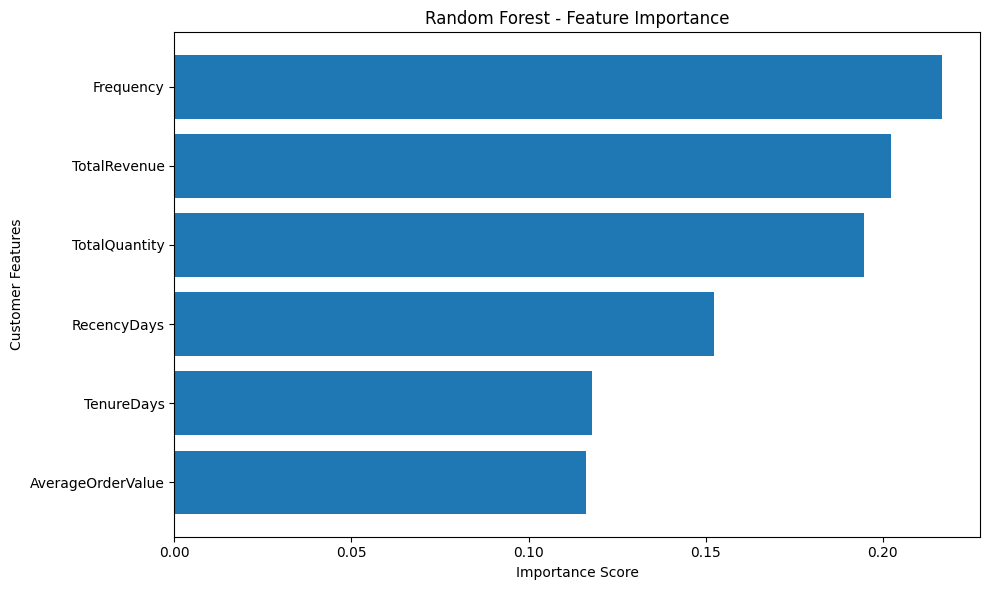

In [30]:

# Module 5 - Feature Importance Analysis

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("FEATURE IMPORTANCE RANKING")
display(feature_importance)

# Visualize the results
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)
plt.xlabel("Importance Score")
plt.ylabel("Customer Features")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [31]:
[name for name in globals()
 if "model" in name.lower() or "lr" in name.lower()]

['model_df',
 'model_data',
 'logistic_model',
 'y_pred_lr',
 'y_prob_lr',
 'rf_model']

In [32]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],

    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf)
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_lr, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0)
    ],

    # ROC-AUC values from your earlier model evaluation
    "ROC-AUC": [0.7156, 0.7226]
})

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.6847,0.5284,0.5602,0.5438,0.7156
1,Random Forest,0.6948,0.5448,0.5489,0.5468,0.7226


In [33]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd

# Train improved models without changing the baseline models
lr_balanced = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

rf_balanced = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

lr_balanced.fit(X_train, y_train)
rf_balanced.fit(X_train, y_train)

# Generate predictions on the same test set
pred_lr_balanced = lr_balanced.predict(X_test)
pred_rf_balanced = rf_balanced.predict(X_test)

# Evaluate each model
results = []

for name, model, predictions in [
    ("Logistic Regression - Balanced", lr_balanced, pred_lr_balanced),
    ("Random Forest - Balanced", rf_balanced, pred_rf_balanced)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, model.predict_proba(X_test)[:, 1]
        )
    })

balanced_results = pd.DataFrame(results)

display(balanced_results.round(4))


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression - Balanced,0.6847,0.5284,0.5602,0.5438,0.7156
1,Random Forest - Balanced,0.7188,0.6335,0.3835,0.4778,0.7004


In [34]:

# ============================================================
# FINAL MODEL COMPARISON - RETAIL SALES ANALYTICS
# ============================================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from IPython.display import display

# Collect the fitted models available in the notebook
models_to_compare = {
    "Logistic Regression": logistic_model,
    "Random Forest": rf_model,
    "Balanced Logistic Regression": lr_balanced
}

# Find the balanced Random Forest model using its existing variable name
balanced_forest_candidates = [
    name for name, obj in globals().items()
    if "balanced" in name.lower()
    and ("forest" in name.lower() or "rf" in name.lower())
    and hasattr(obj, "predict")
    and not name.startswith("_")
]

if len(balanced_forest_candidates) == 1:
    models_to_compare["Balanced Random Forest"] = globals()[
        balanced_forest_candidates[0]
    ]
elif len(balanced_forest_candidates) > 1:
    print("Multiple balanced Random Forest candidates found:")
    print(balanced_forest_candidates)
    print("Select the correct fitted model before continuing.")
else:
    print("Balanced Random Forest was not found.")
    print("Available model-like variables:")
    print([
        name for name, obj in globals().items()
        if hasattr(obj, "predict")
        and not name.startswith("_")
        and any(word in name.lower()
                for word in ["model", "forest", "balanced", "rf"])
    ])

# Evaluate the available fitted models on the same test dataset
results = []

for model_name, model in models_to_compare.items():
    predictions = model.predict(X_test)

    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    if hasattr(model, "predict_proba"):
        scores = model.predict_proba(X_test)[:, 1]
        row["ROC-AUC"] = roc_auc_score(y_test, scores)
    elif hasattr(model, "decision_function"):
        scores = model.decision_function(X_test)
        row["ROC-AUC"] = roc_auc_score(y_test, scores)
    else:
        row["ROC-AUC"] = float("nan")

    results.append(row)

# Rank models by F1-score and display their performance
final_comparison = pd.DataFrame(results)

final_comparison = final_comparison.sort_values(
    by="F1-Score", ascending=False
).reset_index(drop=True)

print("\nFINAL PREDICTIVE MODEL COMPARISON")
display(final_comparison.round(4))

# Identify the model with the highest F1-score
best_model = final_comparison.iloc[0]

print("\nTOP MODEL BY F1-SCORE")
print("Model:", best_model["Model"])
print("F1-Score:", round(best_model["F1-Score"], 4))
print("ROC-AUC:", round(best_model["ROC-AUC"], 4))



FINAL PREDICTIVE MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.6948,0.5448,0.5489,0.5468,0.7226
1,Logistic Regression,0.6847,0.5284,0.5602,0.5438,0.7156
2,Balanced Logistic Regression,0.6847,0.5284,0.5602,0.5438,0.7156
3,Balanced Random Forest,0.7188,0.6335,0.3835,0.4778,0.7004



TOP MODEL BY F1-SCORE
Model: Random Forest
F1-Score: 0.5468
ROC-AUC: 0.7226


In [35]:

# Check the distribution of target classes in the training and test sets

print("Training target distribution:")
display(
    y_train.value_counts()
    .rename("Count")
    .to_frame()
    .assign(
        Percentage=lambda df:
        (df["Count"] / df["Count"].sum() * 100).round(2)
    )
)

print("\nTest target distribution:")
display(
    y_test.value_counts()
    .rename("Count")
    .to_frame()
    .assign(
        Percentage=lambda df:
        (df["Count"] / df["Count"].sum() * 100).round(2)
    )
)


Training target distribution:


,Count,Percentage
RepeatPurchase30D,,
0,2108,66.46
1,1064,33.54



Test target distribution:


,Count,Percentage
RepeatPurchase30D,,
0,527,66.46
1,266,33.54


In [36]:

# Evaluate Random Forest at different prediction thresholds

import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)
from IPython.display import display

# Get predicted probabilities for repeat purchase
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

threshold_results = []

# Compare several thresholds using the same test records
for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:
    predictions = (rf_probabilities >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(threshold_results)

display(
    threshold_results.sort_values(
        "F1-Score", ascending=False
    ).reset_index(drop=True).round(4)
)


,Threshold,Precision,Recall,F1-Score
0,0.40,0.4831,0.6992,0.5714
1,0.35,0.4476,0.7707,0.5663
2,0.45,0.5156,0.6203,0.5631
3,0.50,0.5448,0.5489,0.5468
4,0.30,0.3974,0.8158,0.5345
5,0.55,0.5962,0.4662,0.5232
6,0.60,0.6509,0.4135,0.5057


In [37]:
print("Available model and prediction variables:")

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "model", "threshold", "prob", "x_test", "y_test",
        "x_val", "y_val"
    ]):
        print(name)

Available model and prediction variables:
X_test
best_model
logistic_model
model
model_data
model_df
model_name
models_to_compare
rf_model
rf_probabilities
threshold
threshold_results
y_prob_lr
y_prob_rf
y_test


In [38]:
# Evaluate the Random Forest model using the selected threshold

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
from IPython.display import display

# Use the existing Random Forest model and its test probabilities
selected_model = rf_model
selected_threshold = 0.40

rf_test_probabilities = selected_model.predict_proba(X_test)[:, 1]

# Convert probabilities into repeat-purchase predictions
rf_test_predictions = (
    rf_test_probabilities >= selected_threshold
).astype(int)

# Calculate test-set performance
evaluation_results = pd.DataFrame([{
    "Model": "Random Forest",
    "Threshold": selected_threshold,
    "Accuracy": accuracy_score(y_test, rf_test_predictions),
    "Precision": precision_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "F1-Score": f1_score(
        y_test, rf_test_predictions, zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test, rf_test_probabilities
    )
}])

print("RANDOM FOREST - TEST SET EVALUATION")
display(evaluation_results.round(4))

# Show correct and incorrect predictions for each class
print("\nCONFUSION MATRIX")
print("Rows = Actual classes; Columns = Predicted classes")
display(pd.DataFrame(
    confusion_matrix(y_test, rf_test_predictions),
    index=["Actual: No Repeat Purchase", "Actual: Repeat Purchase"],
    columns=["Predicted: No Repeat Purchase", "Predicted: Repeat Purchase"]
))

# Show precision, recall and F1-score for each class
print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test,
    rf_test_predictions,
    target_names=["No Repeat Purchase", "Repeat Purchase"],
    zero_division=0
))

RANDOM FOREST - TEST SET EVALUATION


,Model,Threshold,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.4,0.6482,0.4831,0.6992,0.5714,0.7226



CONFUSION MATRIX
Rows = Actual classes; Columns = Predicted classes


,Predicted: No Repeat Purchase,Predicted: Repeat Purchase
Actual: No Repeat Purchase,328,199
Actual: Repeat Purchase,80,186



CLASSIFICATION REPORT
                    precision    recall  f1-score   support

No Repeat Purchase       0.80      0.62      0.70       527
   Repeat Purchase       0.48      0.70      0.57       266

          accuracy                           0.65       793
         macro avg       0.64      0.66      0.64       793
      weighted avg       0.70      0.65      0.66       793



TOP 15 FEATURES INFLUENCING REPEAT PURCHASE PREDICTION


,Feature,Importance
0,Frequency,0.2166
1,TotalRevenue,0.2023
2,TotalQuantity,0.1946
3,RecencyDays,0.1524
4,TenureDays,0.1179
5,AverageOrderValue,0.1163


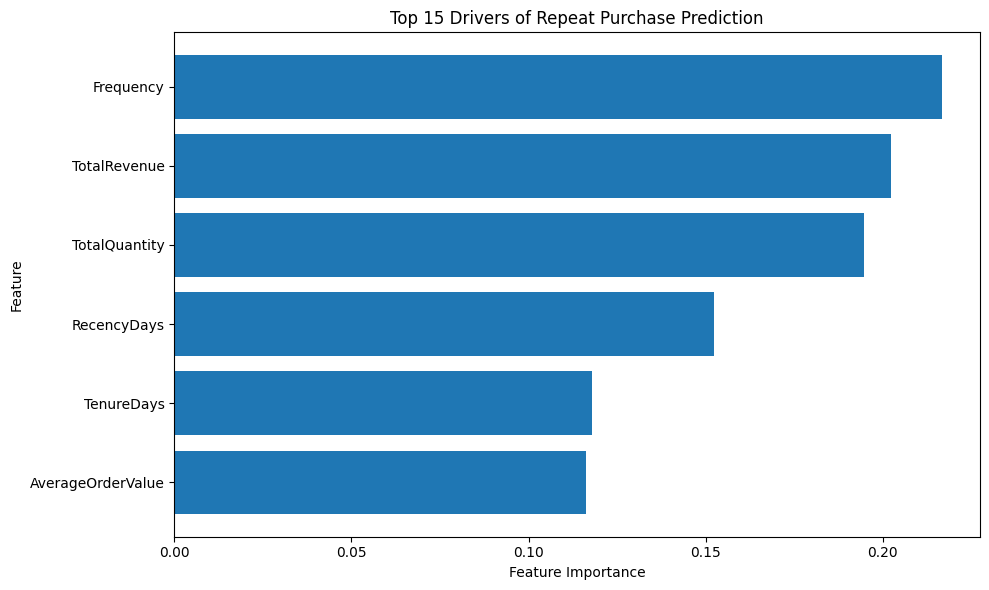

In [39]:

# Identify the most important features in the Random Forest model

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Extract feature importance scores from the trained model
feature_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": rf_model.feature_importances_
})

# Rank features by their contribution to the model
feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
).reset_index(drop=True)

print("TOP 15 FEATURES INFLUENCING REPEAT PURCHASE PREDICTION")
display(feature_importance.head(15).round(4))

# Visualize the most important features
top_features = feature_importance.head(15).sort_values(
    by="Importance", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Drivers of Repeat Purchase Prediction")
plt.tight_layout()
plt.show()


In [40]:

# Check the current predictive modelling setup

import pandas as pd

required_variables = [
    "X_train", "X_test", "y_train", "y_test",
    "logistic_model", "rf_model",
    "RepeatPurchase30D", "sales_df", "model_df", "model_data"
]

print("PREDICTIVE MODELLING AUDIT")
print("-" * 45)

for name in required_variables:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(f"{name}: available | shape = {value.shape}")
        else:
            print(f"{name}: available")
    else:
        print(f"{name}: not found")

print("\nDATE COLUMNS IN AVAILABLE DATAFRAMES")
print("-" * 45)

date_keywords = ["date", "time", "invoice"]

for name in ["sales_df", "model_df", "model_data"]:
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        df = globals()[name]
        date_columns = [
            col for col in df.columns
            if any(word in str(col).lower() for word in date_keywords)
        ]
        print(f"\n{name}: {date_columns}")
        print("Rows:", len(df))


PREDICTIVE MODELLING AUDIT
---------------------------------------------
X_train: available | shape = (3172, 6)
X_test: available | shape = (793, 6)
y_train: available | shape = (3172,)
y_test: available | shape = (793,)
logistic_model: available
rf_model: available
RepeatPurchase30D: not found
sales_df: available | shape = (524878, 9)
model_df: available | shape = (3965, 8)
model_data: available | shape = (3965, 7)

DATE COLUMNS IN AVAILABLE DATAFRAMES
---------------------------------------------

sales_df: ['InvoiceNo', 'InvoiceDate']
Rows: 524878

model_df: []
Rows: 3965

model_data: []
Rows: 3965


In [41]:

# Check the source and cleaning status of the transaction dataset

print("TRANSACTION DATASET AUDIT")
print("-" * 40)

for name in ["transactions", "sales_df"]:
    if name in globals():
        df = globals()[name]
        print(f"\n{name}")
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print("InvoiceDate available:", "InvoiceDate" in df.columns)

        if "InvoiceDate" in df.columns:
            print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())

        if "InvoiceNo" in df.columns:
            print("Unique invoices:", df["InvoiceNo"].nunique())

        if "CustomerID" in df.columns:
            print("Unique customers:", df["CustomerID"].nunique())
    else:
        print(f"\n{name}: not found")


TRANSACTION DATASET AUDIT
----------------------------------------

transactions
Rows: 392692
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
InvoiceDate available: True
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique invoices: 18532
Unique customers: 4338

sales_df
Rows: 524878
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
InvoiceDate available: True
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00
Unique invoices: 19960
Unique customers: 4338


In [42]:

# Check existing validation-related variables

validation_names = [
    "X_val", "y_val",
    "X_valid", "y_valid",
    "X_train", "X_test",
    "y_train", "y_test",
    "rf_probabilities",
    "rf_predictions"
]

print("EXISTING VALIDATION VARIABLES")
print("-" * 40)

for name in validation_names:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(f"{name}: available | shape = {value.shape}")
        else:
            print(f"{name}: available")
    else:
        print(f"{name}: not found")


EXISTING VALIDATION VARIABLES
----------------------------------------
X_val: not found
y_val: not found
X_valid: not found
y_valid: not found
X_train: available | shape = (3172, 6)
X_test: available | shape = (793, 6)
y_train: available | shape = (3172,)
y_test: available | shape = (793,)
rf_probabilities: available | shape = (793,)
rf_predictions: not found


In [43]:

# Module 4 — Create a validation set for threshold selection

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
import numpy as np

# Split existing training data into model-training and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train a separate model for threshold selection
rf_validation_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

rf_validation_model.fit(X_subtrain, y_subtrain)

# Get validation probabilities
val_probabilities = rf_validation_model.predict_proba(X_val)[:, 1]

# Find the threshold with the highest validation F1-score
thresholds = np.arange(0.30, 0.61, 0.05)
threshold_results = []

for threshold in thresholds:
    val_predictions = (val_probabilities >= threshold).astype(int)
    threshold_results.append({
        "Threshold": round(float(threshold), 2),
        "F1": f1_score(y_val, val_predictions, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_results)
display(threshold_results.round(4))

best_threshold = threshold_results.loc[
    threshold_results["F1"].idxmax(), "Threshold"
]

print("Best validation threshold:", best_threshold)


,Threshold,F1
0,0.30,0.5414
1,0.35,0.5320
2,0.40,0.5246
3,0.45,0.5077
4,0.50,0.4986
5,0.55,0.4955
6,0.60,0.4423


Best validation threshold: 0.3


FINAL RANDOM FOREST TEST EVALUATION
Selected validation threshold: 0.3
Accuracy: 0.5233
Precision: 0.3974
Recall: 0.8158
F1-score: 0.5345
ROC-AUC: 0.7226

Classification Report
              precision    recall  f1-score   support

           0       0.80      0.38      0.51       527
           1       0.40      0.82      0.53       266

    accuracy                           0.52       793
   macro avg       0.60      0.60      0.52       793
weighted avg       0.67      0.52      0.52       793



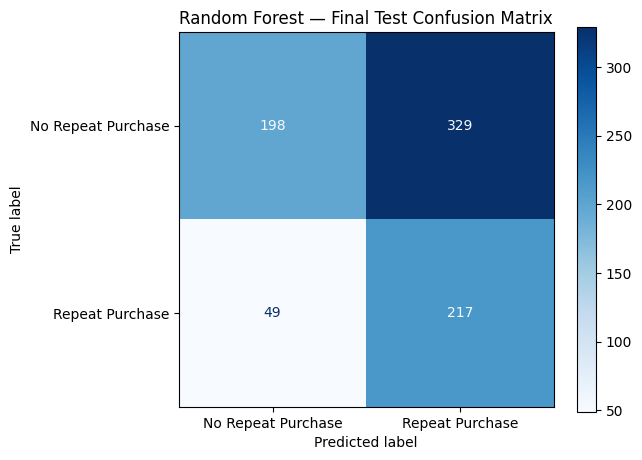

In [44]:

# Module 4 — Final Random Forest evaluation on the test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Generate probabilities for the untouched test set
test_probabilities = rf_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected on validation data
test_predictions = (test_probabilities >= best_threshold).astype(int)

# Evaluate final test performance
print("FINAL RANDOM FOREST TEST EVALUATION")
print("=" * 45)
print("Selected validation threshold:", best_threshold)
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, test_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, test_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, test_probabilities), 4))

print("\nClassification Report")
print(classification_report(y_test, test_predictions, zero_division=0))

# Visualize the test-set confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    display_labels=["No Repeat Purchase", "Repeat Purchase"],
    cmap="Blues"
)
plt.title("Random Forest — Final Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [45]:

# Module 5 - Verify dashboard inputs

dashboard_inputs = [
    "transactions",
    "sales_df",
    "model_df",
    "model_data",
    "rf_model",
    "logistic_model",
    "best_threshold"
]

for name in dashboard_inputs:
    if name in globals():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(f"{name}: available | shape = {value.shape}")
        else:
            print(f"{name}: available | type = {type(value).__name__}")
    else:
        print(f"{name}: not available")

print("\nExisting segmentation dataframes:")

for name, value in list(globals().items()):
    if name.startswith("_") or not hasattr(value, "columns"):
        continue

    columns = list(value.columns)
    matched = [
        col for col in columns
        if any(word in str(col).lower()
               for word in ["segment", "cluster", "rfm"])
    ]

    if matched:
        print(f"{name}: {matched}")


transactions: available | shape = (392692, 9)
sales_df: available | shape = (524878, 9)
model_df: available | shape = (3965, 8)
model_data: available | shape = (3965, 7)
rf_model: available | type = RandomForestClassifier
logistic_model: available | type = Pipeline
best_threshold: available | shape = ()

Existing segmentation dataframes:
data: ['Cluster']
rfm_df: ['Cluster']


In [46]:

# Module 5 - Verify Dashboard Inputs

dashboard_inputs = [
    "df_original",
    "df",
    "sales_df",
    "transactions",
    "model_df",
    "model_data",
    "rf_model",
    "logistic_model",
    "best_threshold"
]

for name in dashboard_inputs:
    if name not in globals():
        print(f"MISSING: {name}")
        continue

    obj = globals()[name]

    if hasattr(obj, "shape"):
        print(f"READY: {name} | shape = {obj.shape}")
    else:
        print(f"READY: {name} | type = {type(obj).__name__}")

print("\n--- Model target and segmentation columns ---")

for name, obj in list(globals().items()):
    if name.startswith("_") or not hasattr(obj, "columns"):
        continue

    columns = list(obj.columns)

    relevant = [
        col for col in columns
        if any(term in str(col).lower()
               for term in ["repeatpurchase", "segment", "cluster", "rfm"])
    ]

    if relevant:
        print(f"{name}: {relevant}")


READY: df_original | shape = (541909, 8)
READY: df | shape = (524878, 9)
READY: sales_df | shape = (524878, 9)
READY: transactions | shape = (392692, 9)
READY: model_df | shape = (3965, 8)
READY: model_data | shape = (3965, 7)
READY: rf_model | type = RandomForestClassifier
READY: logistic_model | type = Pipeline
READY: best_threshold | shape = ()

--- Model target and segmentation columns ---
data: ['Cluster']
rfm_df: ['Cluster']
features: ['RepeatPurchase30D']
model_df: ['RepeatPurchase30D']
model_data: ['RepeatPurchase30D']


In [47]:

# Module 5 - Inspect dashboard data structures

dataframes_to_check = [
    "transactions",
    "sales_df",
    "data",
    "rfm_df",
    "model_df",
    "model_data"
]

for name in dataframes_to_check:
    obj = globals().get(name)

    if obj is not None and hasattr(obj, "columns"):
        print(f"\n--- {name} ---")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

# Inspect customer cluster assignments
for name in ["data", "rfm_df"]:
    obj = globals().get(name)

    if obj is not None and "Cluster" in obj.columns:
        print(f"\n--- {name}: Cluster counts ---")
        print(obj["Cluster"].value_counts(dropna=False).sort_index())

# Confirm model features and selected threshold
print("\n--- Model configuration ---")
print("Random Forest features:",
      getattr(rf_model, "feature_names_in_", "Not stored"))

if hasattr(logistic_model, "feature_names_in_"):
    print("Logistic Regression features:",
          logistic_model.feature_names_in_.tolist())
elif hasattr(logistic_model, "named_steps"):
    print("Logistic Regression pipeline steps:",
          list(logistic_model.named_steps.keys()))

print("Selected threshold:", best_threshold)



--- transactions ---
Shape: (392692, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

--- sales_df ---
Shape: (524878, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

--- data ---
Shape: (1166, 5)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Cluster']

--- rfm_df ---
Shape: (4338, 5)
Columns: ['CustomerID', 'Recency', 'Frequency', 'Monetary', 'Cluster']

--- model_df ---
Shape: (3965, 8)
Columns: ['CustomerID', 'RecencyDays', 'TenureDays', 'Frequency', 'TotalRevenue', 'TotalQuantity', 'AverageOrderValue', 'RepeatPurchase30D']

--- model_data ---
Shape: (3965, 7)
Columns: ['RecencyDays', 'TenureDays', 'Frequency', 'TotalRevenue', 'TotalQuantity', 'AverageOrderValue', 'RepeatPurchase30D']

--- data: Cluster counts ---
Cluster
3    1166
Name: count, dtype: int64

--- rfm_df: Cluster counts ---
Cluster
0     71

In [48]:

# Module 5 - Export dashboard data and models

from pathlib import Path
import joblib
import json
import pandas as pd

output_dir = Path("/content/retail_dashboard")
output_dir.mkdir(parents=True, exist_ok=True)

# Save transaction and customer data for the dashboard
transactions.to_csv(
    output_dir / "transactions.csv.gz",
    index=False,
    compression="gzip"
)

rfm_df.to_csv(
    output_dir / "customer_segments.csv",
    index=False
)

# Add repeat-purchase probabilities using the existing models
feature_cols = [
    "RecencyDays",
    "TenureDays",
    "Frequency",
    "TotalRevenue",
    "TotalQuantity",
    "AverageOrderValue"
]

customer_predictions = model_df[
    ["CustomerID"] + feature_cols + ["RepeatPurchase30D"]
].copy()

customer_predictions["RandomForestProbability"] = (
    rf_model.predict_proba(customer_predictions[feature_cols])[:, 1]
)

customer_predictions["LogisticRegressionProbability"] = (
    logistic_model.predict_proba(customer_predictions[feature_cols])[:, 1]
)

customer_predictions["RandomForestPrediction"] = (
    customer_predictions["RandomForestProbability"] >= best_threshold
).astype(int)

customer_predictions.to_csv(
    output_dir / "customer_predictions.csv",
    index=False
)

# Save the trained models and their prediction threshold
joblib.dump(rf_model, output_dir / "random_forest.joblib")
joblib.dump(logistic_model, output_dir / "logistic_regression.joblib")

with open(output_dir / "config.json", "w") as f:
    json.dump({"prediction_threshold": float(best_threshold)}, f)

print("Dashboard files exported successfully:")
for path in sorted(output_dir.iterdir()):
    print(f"{path.name}: {path.stat().st_size / (1024 * 1024):.2f} MB")


Dashboard files exported successfully:
config.json: 0.00 MB
customer_predictions.csv: 0.31 MB
customer_segments.csv: 0.10 MB
logistic_regression.joblib: 0.00 MB
random_forest.joblib: 3.27 MB
transactions.csv.gz: 6.29 MB


In [49]:

# Module 5 - Package dashboard files for download

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/UCI_Online_Retail_Dashboard",
    "zip",
    root_dir="/content/retail_dashboard"
)

print("Dashboard package created successfully.")
print("File:", zip_path)

files.download(zip_path)


Dashboard package created successfully.
File: /content/UCI_Online_Retail_Dashboard.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:

# Module 5 - Export sales data for Power BI

transactions.to_csv(
    "/content/retail_dashboard/transactions.csv",
    index=False
)

print("Power BI sales dataset exported.")


Power BI sales dataset exported.


In [51]:

# Module 5 - Export dashboard datasets

from pathlib import Path
import zipfile
from google.colab import files

output_dir = Path("/content/retail_dashboard")
output_dir.mkdir(parents=True, exist_ok=True)

# Export cleaned transaction data
transactions.to_csv(
    output_dir / "transactions.csv",
    index=False
)

# Export customer segments
segment_source = rfm_df if "rfm_df" in globals() else data

segment_source.to_csv(
    output_dir / "customer_segments.csv",
    index=False
)

# Export customer repurchase predictions
customer_predictions.to_csv(
    output_dir / "customer_predictions.csv",
    index=False
)

# Package the exported datasets
zip_path = Path("/content/UCI_Online_Retail_PowerBI_Data.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file_path in output_dir.glob("*.csv"):
        zip_file.write(file_path, arcname=file_path.name)

# Verify exported files
print("Exported files:")
for file_path in sorted(output_dir.glob("*.csv")):
    print(f"{file_path.name}: {file_path.stat().st_size / (1024 * 1024):.2f} MB")

print("\nDownloading dashboard datasets...")
files.download(str(zip_path))


Exported files:
customer_predictions.csv: 0.31 MB
customer_segments.csv: 0.10 MB
transactions.csv: 36.67 MB



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>